# 12 — Dự báo và gợi ý có giải thích

**Câu hỏi:** một hồ sơ đi qua model thật và bộ quy tắc như thế nào?

Chạy notebook 11 trước. Model 75% được giữ nguyên. HCO–VNLS chọn đặc trưng; G01–G04 là quy tắc giải thích được, không phải chiến lược đã được thuật toán tối ưu.

In [1]:
from pathlib import Path
import json
import os
import sys
import pandas as pd
from IPython.display import display

current = Path.cwd()
ROOT = next(parent for parent in [current, *current.parents] if (parent / 'apps/backend/app').is_dir())
sys.path.insert(0, str(ROOT / 'apps'))
sys.path.insert(0, str(ROOT / 'apps/backend'))
RESEARCH = Path(os.environ.get('CLHT_RESEARCH_DATA', str(ROOT.parent / 'CLHT_GB_GITHUB')))
OUTPUT = ROOT / 'apps/research_outputs'
FIGURES = OUTPUT / 'hinh'
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print('Mốc phục vụ app: 75%. Không đổi model và không dùng nhãn cuối kỳ để sinh gợi ý.')


Mốc phục vụ app: 75%. Không đổi model và không dùng nhãn cuối kỳ để sinh gợi ý.


## 1. Chạy đúng API dùng trong app

TestClient gọi cùng FastAPI trong tiến trình, không dùng server hay kết quả giả. Hồ sơ thiếu xác nhận dữ liệu phải trả trạng thái từ chối; không gán xác suất 0%.

In [2]:
from fastapi.testclient import TestClient
from app.main import app
from app.services.support import demo_cases
client = TestClient(app)
responses = []
for case in demo_cases():
    response = client.post('/api/v1/support/cases/' + case['id'])
    assert response.status_code == 200, response.text
    output = response.json()
    responses.append(output)
    if case['source_kind'] == 'synthetic_test':
        assert output['prediction'] is None and not output['suggestions']
    else:
        assert 0 <= output['prediction']['probability_risk'] <= 1
rows = []
for output in responses:
    rows.append({'tình huống': output['case_title'],
        'nguy cơ ước lượng': None if output['prediction'] is None else output['prediction']['probability_risk'],
        'quy tắc khớp': ', '.join(item['rule_id'] for item in output['suggestions']) or 'Không có',
        'trạng thái': output['status'], 'thời gian ms': output['runtime_ms']})
summary = pd.DataFrame(rows)
display(summary)
summary.to_csv(OUTPUT / 'ket_qua_demo.csv', index=False, encoding='utf-8-sig')
(OUTPUT / 'ket_qua_demo.json').write_text(json.dumps(responses, ensure_ascii=False, indent=2), encoding='utf-8')

,tình huống,nguy cơ ước lượng,quy tắc khớp,trạng thái,thời gian ms
0,Cần kiểm tra bài đến hạn,0.183197,G01,available,2553.83
1,"Đã nộp đủ, từng nộp trễ",0.081213,G02,available,10.47
2,Một tuần chưa có tương tác,0.316892,"G03, G02",available,9.79
3,Một tháng chưa có tương tác,0.329797,"G04, G02",available,10.51
4,Nộp sớm không bù được bài thiếu,0.074607,"G01, G02",available,11.76
5,Chưa có tình huống cần gợi ý,0.029254,Không có,abstained,9.00
6,Thiếu bằng chứng: hệ thống từ chối,NaN,Không có,abstained,0.02


14558

**Đọc kết quả:** xác suất thấp không chặn một gợi ý có căn cứ. Không có quy tắc khớp không có nghĩa chắc chắn học tốt. Thời gian lần chạy này gồm nạp model khi cache lạnh, không dùng để tuyên bố benchmark.

## 2. Mổ xẻ trường hợp nộp sớm

Đọc số bài đến hạn, số đã hoàn thành trong đúng tập bài đó và mã cần kiểm tra. Sau đó mới đọc lời khuyên. Không dùng số tổng nộp/đến hạn làm tỷ lệ hoàn thành.

In [3]:
early = next(item for item in responses if item['case_id'] == 'nop-som')
display(pd.DataFrame([early['assessment_summary']]))
for suggestion in early['suggestions']:
    print(suggestion['rule_id'], suggestion['title'])
    print('Quan sát:', suggestion['observation'])
    print('Căn cứ:', ' | '.join(suggestion['evidence']))
    print('Hành động:', suggestion['action'])
    print('Giới hạn:', suggestion['limitation'], '\n')
assert early['assessment_summary']['missing'] > 0
assert early['assessment_summary']['early_future'] > 0

,due,submitted,completed_due,missing,late,missing_ids,late_ids,unknown_deadlines,exempt_due,early_future
0,9,9,8,1,4,[B06],"[B03, B05, B07, B09]",1,0,1


G01 Kiểm tra các bài đến hạn
Quan sát: 1 bài đến hạn chưa có bản ghi hoàn thành.
Căn cứ: 9 bài có hạn không sau ngày 180. | 8 bài trong số đó đã có bản ghi nộp. | Mã minh họa cần kiểm tra: B06
Hành động: Kiểm tra trạng thái từng bài. Nếu thực sự còn thiếu, trao đổi với giảng viên về cách hoàn thành hoặc hỗ trợ phù hợp.
Giới hạn: Hạn chung có thể khác gia hạn cá nhân. Không khẳng định vẫn được nộp muộn hoặc điểm sẽ tăng. 

G02 Sắp xếp tiến độ nộp bài
Quan sát: 4 bài mới từng được nộp sau hạn chung.
Căn cứ: Mã minh họa nộp trễ: B03, B05, B07, B09 | Chỉ đếm bài đã nộp đến cutoff; không tính bài bảo lưu hoặc được miễn.
Hành động: Nếu lịch học đang khó sắp xếp, thử chia bài thành các bước và đặt lịch nhắc trước hạn; xác nhận nguyên nhân trước khi điều chỉnh.
Giới hạn: Từng nộp trễ không đồng nghĩa kiến thức yếu. Gia hạn cá nhân có thể chưa có trong dữ liệu. 



## 3. Hình minh họa kết quả dự báo

Biểu đồ chỉ mô tả sáu đầu vào demo, không phải Accuracy/AP hay đánh giá trên test. Hồ sơ thiếu dữ liệu không được vẽ thành nguy cơ bằng 0.

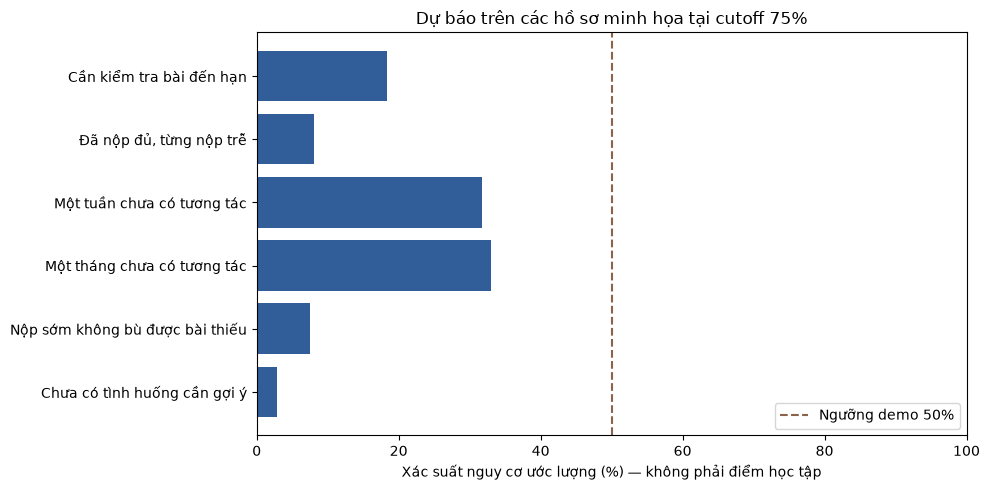

In [4]:
import matplotlib.pyplot as plt
valid = summary.dropna(subset=['nguy cơ ước lượng'])
figure, axis = plt.subplots(figsize=(10, 5))
axis.barh(valid['tình huống'], valid['nguy cơ ước lượng'] * 100, color='#315d98')
axis.axvline(50, color='#8b634b', linestyle='--', label='Ngưỡng demo 50%')
axis.set_xlim(0, 100)
axis.set_xlabel('Xác suất nguy cơ ước lượng (%) — không phải điểm học tập')
axis.set_title('Dự báo trên các hồ sơ minh họa tại cutoff 75%')
axis.invert_yaxis()
axis.legend(loc='lower right')
figure.tight_layout()
figure.savefig(FIGURES / 'du_bao_ho_so_minh_hoa.png', dpi=160, bbox_inches='tight')
display(figure)
plt.close(figure)

## 4. Bài tập và kết luận

Nếu xác suất chỉ 1% nhưng có bài đến hạn chưa có bản ghi, nên ẩn gợi ý không? Không. Gợi ý kiểm tra bài dựa trên mã bài cụ thể, không bị khóa bởi ngưỡng nguy cơ. Kiểm thử điều này nằm trong notebook 13. Chưa có thí nghiệm cho thấy lời khuyên tăng điểm.